# 01. Exploratory Data Analysis & Preprocessing
**Team Member**: Data Engineer (Member 1)
**Objective**: Ingest retail marketing data (or synthetic benchmark), clean missing values, examine confounders, and engineer feature pipelines.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.data.synthetic import generate_synthetic_data
from src.data.preprocess import clean_data, preprocess_features
from src.data.features import engineer_features
from src.utils.config import Config

# Load synthetic dataset with known ground-truth ITE
df = generate_synthetic_data(n_samples=10000, random_state=42)
df.head()

,CustomerID,Age,PriorSpend,VisitFrequency,LoyaltyScore,Discount,Sales,EstimatedItemPrice,TrueITE,TruePropensity
0,1,44.0,46.50,4,5.47,1,254.66,131.26,33.47,0.3975
1,2,36.3,13.05,4,4.89,0,197.16,120.01,33.76,0.4643
2,3,45.8,10.00,5,3.58,0,193.47,107.96,36.09,0.4270
3,4,56.3,11.88,4,1.51,1,198.99,102.64,34.78,0.4748
4,5,35.2,104.92,7,1.39,0,215.68,121.46,37.26,0.3771


In [2]:
# Check distributions and summary statistics
df.describe()

,CustomerID,Age,PriorSpend,VisitFrequency,LoyaltyScore,Discount,Sales,EstimatedItemPrice,TrueITE,TruePropensity
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,5000.50000,38.216160,123.578945,4.025400,2.871764,0.424500,228.605545,127.712683,31.68496,0.430223
std,2886.89568,11.516777,122.383880,1.963298,1.581877,0.494292,61.958309,31.474877,4.36024,0.117071
min,1.00000,18.000000,10.000000,1.000000,0.030000,0.000000,61.630000,59.750000,9.42000,0.050000
25%,2500.75000,29.900000,35.735000,3.000000,1.630000,0.000000,186.817500,106.300000,28.92750,0.352400
50%,5000.50000,38.000000,85.915000,4.000000,2.665000,0.000000,220.000000,121.970000,31.64000,0.435750
75%,7500.25000,46.100000,169.865000,5.000000,3.930000,1.000000,260.000000,142.990000,34.47000,0.516500
max,10000.00000,75.000000,1000.000000,14.000000,8.920000,1.000000,630.360000,336.400000,50.90000,0.725400


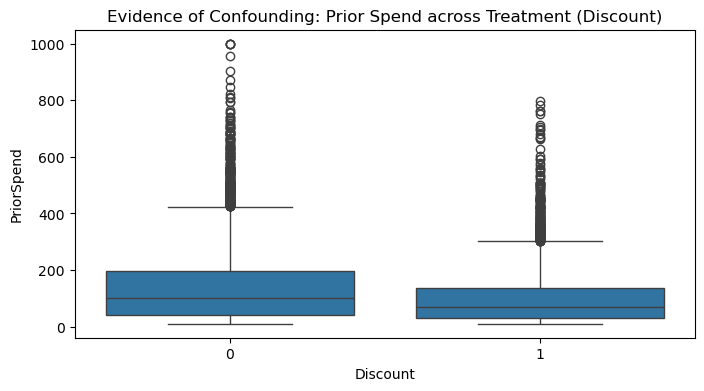

In [3]:
# Inspect Confounder Correlations: Prior Spend vs Discount probability
plt.figure(figsize=(8, 4))
sns.boxplot(x="Discount", y="PriorSpend", data=df)
plt.title("Evidence of Confounding: Prior Spend across Treatment (Discount)")
plt.show()

In [4]:
# Feature engineering and preprocessing
df_feat = engineer_features(df)
df_clean = clean_data(df_feat)
# Save processed artifact
df_clean.to_parquet(Config.PROCESSED_DATA_DIR / "customers_processed.parquet", index=False)
print("Processed data saved successfully.")

[2026-10-21 15:54:34] [INFO] [Preprocess]: Cleaned data: dropped 0 rows with missing values.


Processed data saved successfully.
